<a href="https://colab.research.google.com/github/JaafarBK02/satellite-cnn-vit/blob/main/03_evaluate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, sys, numpy as np, torch, torchvision
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'

from google.colab import drive
drive.mount('/content/drive')
CACHE = '/content/drive/MyDrive/tile2vec_data/features.npz'

if not os.path.exists('tile2vec'):
    !git clone -q https://github.com/ermongroup/tile2vec.git
if not os.path.exists('tile2vec/data/tiles/1tile.npy'):
    !cd tile2vec/data && unzip -nq tiles.zip

d = np.load(CACHE)
X, y, X_raw, X_imagenet = d['X'], d['y'], d['X_raw'], d['X_imagenet']

def evaluate_trials(X, y, make_model, n_trials=100, n_train=None):
    accs, f1s = [], []
    for i in range(n_trials):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=i)
        if n_train is not None:
            X_tr, y_tr = X_tr[:n_train], y_tr[:n_train]
        p = make_model(i).fit(X_tr, y_tr).predict(X_te)
        accs.append(accuracy_score(y_te, p))
        f1s.append(f1_score(y_te, p, average='macro', zero_division=0))
    return np.array(accs), np.array(f1s)

rf = lambda i: RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=i)
lr = lambda i: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
print('Ready on', device, '|', X.shape, X_imagenet.shape, y.shape)

Mounted at /content/drive
Ready on cpu | (1000, 512) (1000, 512) (1000,)


In [ ]:
CKPT_DIR = '/content/drive/MyDrive/tile2vec_data/checkpoints'
!ls -lh {CKPT_DIR}

total 1.2G
-rw------- 1 root root 240M Nov 19 21:36 ours_epoch10.pt
-rw------- 1 root root 240M Nov 19 19:27 ours_epoch1.pt
-rw------- 1 root root 240M Nov 20 00:00 ours_epoch20.pt
-rw------- 1 root root 240M Nov 20 00:15 ours_epoch21.pt
-rw------- 1 root root 240M Nov 19 20:24 ours_epoch5.pt


In [ ]:
import glob
sys.path.append('tile2vec')
from src.tilenet import make_tilenet

epoch_of = lambda p: int(p.split('epoch')[1].split('.')[0])
ckpts = sorted(glob.glob(f'{CKPT_DIR}/ours_epoch*.pt'), key=epoch_of)
LAST = ckpts[-1]

# All 1,000 labeled tiles, 4 bands, scaled 0-1 (same preprocessing as the pretrained model)
tiles4 = np.stack([np.load(f'tile2vec/data/tiles/{i+1}tile.npy')[:, :, :4] for i in range(1000)])
t4 = torch.from_numpy(np.moveaxis(tiles4.astype(np.float32), -1, 1) / 255.0)

def embed(ckpt_path):
    ck = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    net = make_tilenet(in_channels=4, z_dim=512)
    net.load_state_dict(ck['model']); net.eval()
    with torch.no_grad():
        Z = np.concatenate([net.encode(t4[b:b+100]).numpy() for b in range(0, 1000, 100)])
    return Z, ck

X_ours, ck = embed(LAST)
EPOCH = ck['epoch']
np.save(f'/content/drive/MyDrive/tile2vec_data/X_ours_epoch{EPOCH}.npy', X_ours)
print(f'My model after {EPOCH} epochs, last training loss {ck["history"][-1]["loss"]:.4f}\n')

for clf, m in [('RF', rf), ('LR', lr)]:
    a_ours, f_ours = evaluate_trials(X_ours, y, m)
    a_pre,  f_pre  = evaluate_trials(X,      y, m)
    print(f'{clf}: mine {a_ours.mean():.4f} ± {a_ours.std():.4f} (macro F1 {f_ours.mean():.3f}) | '
          f'pretrained {a_pre.mean():.4f} (F1 {f_pre.mean():.3f}) | '
          f'gap {np.mean(a_ours - a_pre):+.4f}, p = {wilcoxon(a_ours, a_pre).pvalue:.1e}')

My model after 21 epochs, last training loss 3.2231

RF: mine 0.7221 ± 0.0311 (macro F1 0.367) | pretrained 0.7174 (F1 0.393) | gap +0.0047, p = 2.2e-02
LR: mine 0.7137 ± 0.0277 (macro F1 0.383) | pretrained 0.7025 (F1 0.410) | gap +0.0111, p = 2.6e-05


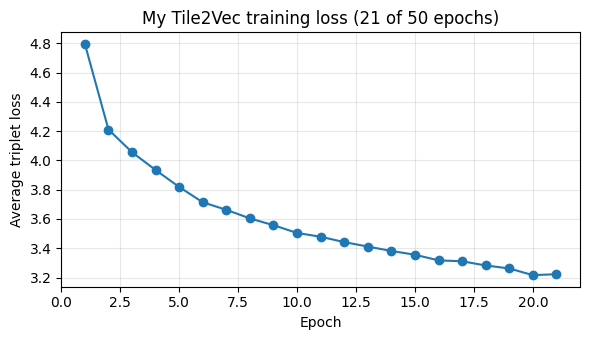

In [ ]:
hist = ck['history']
plt.figure(figsize=(6, 3.5))
plt.plot([h['epoch'] for h in hist], [h['loss'] for h in hist], marker='o')
plt.xlabel('Epoch'); plt.ylabel('Average triplet loss')
plt.title(f'My Tile2Vec training loss ({EPOCH} of 50 epochs)')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

epoch  1: accuracy 0.6607, macro F1 0.317
epoch  5: accuracy 0.6865, macro F1 0.330
epoch 10: accuracy 0.7192, macro F1 0.355
epoch 20: accuracy 0.7280, macro F1 0.378
epoch 21: accuracy 0.7278, macro F1 0.382


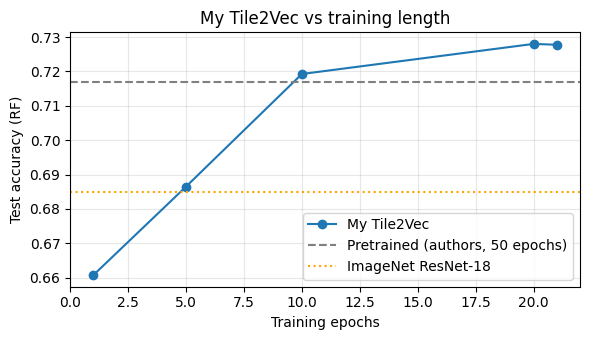

In [ ]:
rows = []
for p in ckpts:
    Z, c = embed(p)
    a, f = evaluate_trials(Z, y, rf, n_trials=20)
    rows.append((c['epoch'], a.mean(), f.mean()))
    print(f'epoch {c["epoch"]:2d}: accuracy {a.mean():.4f}, macro F1 {f.mean():.3f}')

plt.figure(figsize=(6, 3.5))
plt.plot([r[0] for r in rows], [r[1] for r in rows], marker='o', label='My Tile2Vec')
plt.axhline(0.717, ls='--', color='gray', label='Pretrained (authors, 50 epochs)')
plt.axhline(0.685, ls=':', color='orange', label='ImageNet ResNet-18')
plt.xlabel('Training epochs'); plt.ylabel('Test accuracy (RF)')
plt.title('My Tile2Vec vs training length'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()